# 3D Point Cloud Segmentation
Segment exactly one sphere (yellow) and multiple planes (distinct colors) from `.pcd` to `.ply` using RANSAC from scratch.


## Parameters

Change these values and rerun the notebook from the top. The distance and support defaults are starting values for the experiment.

In [1]:
INPUT_FRAME = None          # None -> All PCD files here | "Frame4994.pcd" -> Specific File.
MAX_PLANES = 4              # Use 1 for one plane, or None to stop by support alone.
PLANE_TOLERANCE_MM = 6.0    # Maximum perpendicular distance for an inlier.
MIN_PLANE_FRACTION = 0.03   # Minimum support as a fraction of the original valid points.
RANSAC_TRIALS = 150         # Random triples tried per plane.
RANDOM_SEED = 42            # Repeat the same random draws on each run.
SPHERE_TRIALS = 800         # Local four-point proposals per frame.
SPHERE_TOLERANCE_MM = 5.0   # Accepted distance from the sphere surface.

## 1. Custom PCD Parser
- Reads ASCII PCD files directly.
- Extracts spatial $(x, y, z)$ coordinates only; filters invalid sensor depth ($z \le 0$).

In [ ]:
import os
import math
import numpy as np

def read_pcd(file_path, filter_zeros=True):
    """Reads ASCII PCD file returning (N, 3) spatial coordinates."""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"File not found: {file_path}")
        
    header = {}
    data_started = False
    points_list = []
    
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            
            if not line or line.startswith('#'):
                continue
                
            if not data_started:
                tokens = line.split()
                keyword = tokens[0].upper()
                
                if keyword == 'DATA':
                    header['DATA'] = tokens[1] if len(tokens) > 1 else 'ascii'
                    
                    if header['DATA'].lower() != 'ascii':
                        raise ValueError("Expected an ASCII PCD file.")
                    
                    fields = header.get('FIELDS', [])
                    counts = list(map(int, header.get('COUNT', ['1'] * len(fields))))
                    columns = [sum(counts[:fields.index(axis)]) for axis in ('x', 'y', 'z')]
                    data_started = True
                    
                else:
                    header[keyword] = tokens[1:]
                    
            else:
                parts = line.split()
                points_list.append([float(parts[i]) for i in columns])
                    
    points = np.array(points_list, dtype=np.float64).reshape(-1, 3)
    raw_count = len(points)
    
    if filter_zeros and len(points) > 0:
        
        valid_mask = np.isfinite(points).all(axis=1) & (points[:, 2] > 0.0) & (np.linalg.norm(points, axis=1) > 1e-3)
        points = points[valid_mask]
        
    return points, header, raw_count

In [3]:
from pathlib import Path

folder = Path.cwd()
if (folder / "FIRST_ASSIGNMENT" / "Assignment.ipynb").is_file():
    folder = folder / "FIRST_ASSIGNMENT"

if INPUT_FRAME is None:
    frame_paths = sorted(folder.glob("*.pcd"))
else:
    path = Path(INPUT_FRAME)
    frame_paths = [path if path.is_file() else folder / path]

if not frame_paths:
    raise FileNotFoundError(f"No PCD files found in {folder}")
print(f"Selected {len(frame_paths)} frame(s).")

Selected 11 frame(s).


## 2. Test one candidate plane

In [4]:
# Three non-collinear points define a plane. 
A = np.array([10, 20, 500])
B = np.array([30, 20, 500])
C = np.array([10, 50, 500])

# Candidate Point
Q = np.array([200, 100, 498])

normal = np.cross(B - A, C - A)
unit_normal = normal / np.linalg.norm(normal)
distance_mm = abs(np.dot(Q - A, unit_normal))

# Example one
tolerance_mm = 3

print(f"Distance to plane: {distance_mm:g} mm")
print(f"Within tolerance: {distance_mm <= tolerance_mm}")

Distance to plane: 2 mm
Within tolerance: True


## 3. Find planes in the frame ( RANSAC random triples )

Strategy ( As we did in the LAB ) removing the winning inliers before repeating the search otherwise we could identify the same surface multiple times but with different random triplets.

Tollerance?
- wider -> admits noisier measurements but can merge nearby surfaces. 
- lower -> more precise but noise could be a problem.

In [5]:
def find_plane(cloud, tolerance_mm, trials, rng):
    """Return the strongest sampled plane (unit normal, offset) and its inlier mask."""
    best_plane = None
    best_mask = np.zeros(len(cloud), dtype=bool)
    best_count = 0

    for _ in range(trials):
        a, b, c = cloud[rng.choice(len(cloud), size=3, replace=False)]
        normal = np.cross(b - a, c - a)
        length = np.linalg.norm(normal)
        if length < 1e-10:
            continue
        normal = normal / length
        offset = normal @ a
        mask = np.abs(cloud @ normal - offset) <= tolerance_mm
        count = np.count_nonzero(mask)
        if count > best_count:
            best_plane = (normal, offset)
            best_mask = mask
            best_count = count

    return best_plane, best_mask

In [6]:
def segment_planes(points, sphere_mask=None, tolerance_mm=None, max_planes=MAX_PLANES, refine=False):
    if tolerance_mm is None:
        tolerance_mm = PLANE_TOLERANCE_MM
    rng = np.random.default_rng(RANDOM_SEED)
    plane_labels = np.zeros(len(points), dtype=int)
    if sphere_mask is not None:
        plane_labels[sphere_mask] = -1  # Reserve sphere points before fitting planes.
    remaining = np.flatnonzero(plane_labels == 0)
    planes = []
    min_points = max(3, math.ceil(MIN_PLANE_FRACTION * len(points)))

    while len(remaining) >= min_points and (max_planes is None or len(planes) < max_planes):
        plane, mask = find_plane(points[remaining], tolerance_mm, RANSAC_TRIALS, rng)
        count = np.count_nonzero(mask)
        if count < min_points:
            break
        if refine:
            cloud = points[remaining]
            normal, offset = refit_plane(cloud[mask])
            refined_mask = np.abs(cloud @ normal - offset) <= tolerance_mm
            if np.count_nonzero(refined_mask) >= min_points:
                plane, mask = (normal, offset), refined_mask
        planes.append(plane)
        plane_labels[remaining[mask]] = len(planes)
        remaining = remaining[~mask]
    return planes, plane_labels

frame_results = {}
for path in frame_paths:
    points, header, raw_count = read_pcd(path)
    planes, labels = segment_planes(points)
    frame_results[path.name] = (points, planes, labels)
    print(f"{path.name}: {len(points):,}/{raw_count:,} valid points, {len(planes)} planes")

Frame15439.pcd: 217,043/217,088 valid points, 4 planes
Frame18031.pcd: 216,702/217,088 valid points, 4 planes
Frame4994.pcd: 215,659/217,088 valid points, 4 planes
Frame5551.pcd: 217,056/217,088 valid points, 4 planes
Frame5922.pcd: 217,028/217,088 valid points, 4 planes
Frame7183.pcd: 217,009/217,088 valid points, 4 planes
Frame7735.pcd: 217,073/217,088 valid points, 4 planes
Frame8078.pcd: 217,088/217,088 valid points, 4 planes
Frame9387.pcd: 217,088/217,088 valid points, 4 planes
Frame9592.pcd: 217,088/217,088 valid points, 4 planes
Frame9876.pcd: 217,080/217,088 valid points, 4 planes


## 4. Inspect the plane labels

In the camera view, divide x and y by depth z to see the direction of each measurement. In the side view, keep depth so you can see surfaces at different distances. Look for broad patches of one color. Several narrow bands across one surface can mean RANSAC has split it. Grey points are still unassigned.

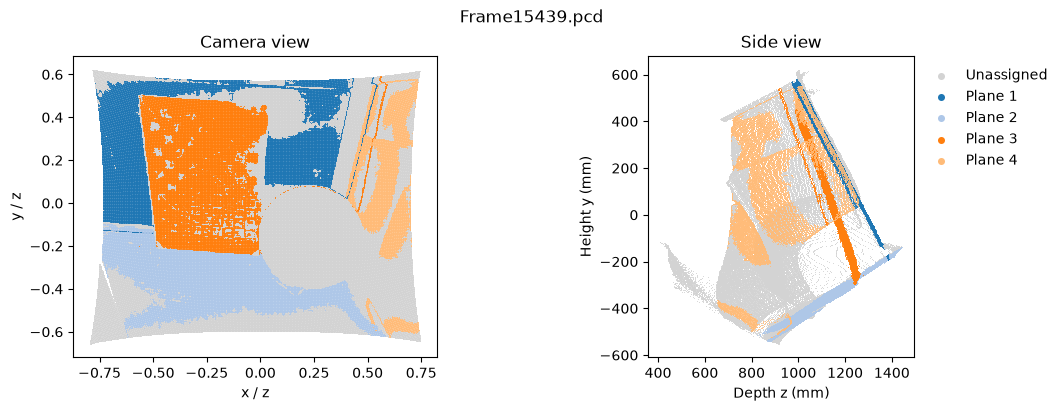

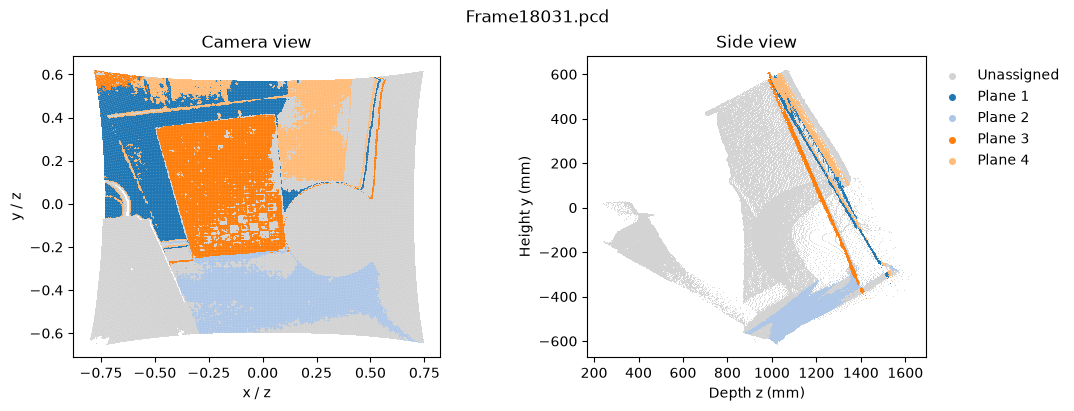

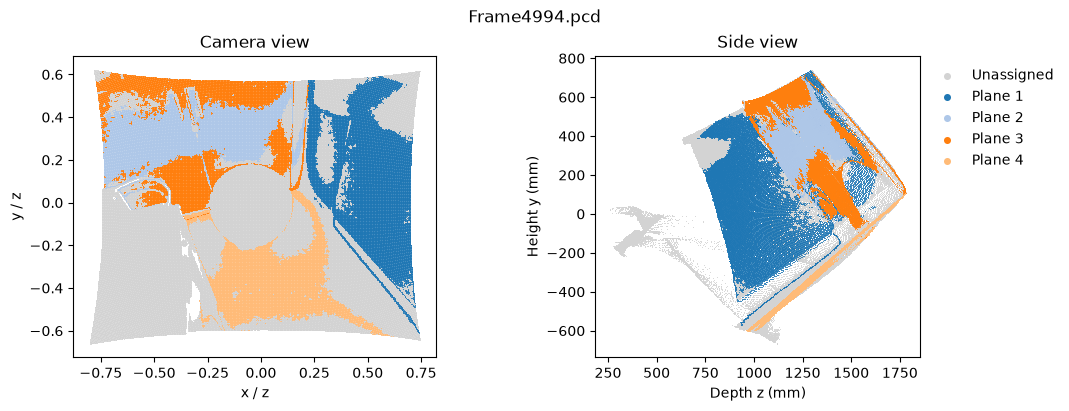

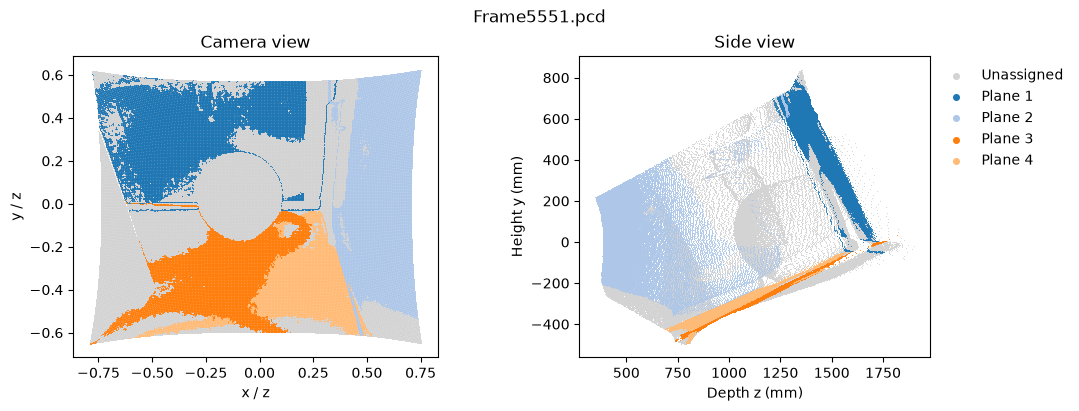

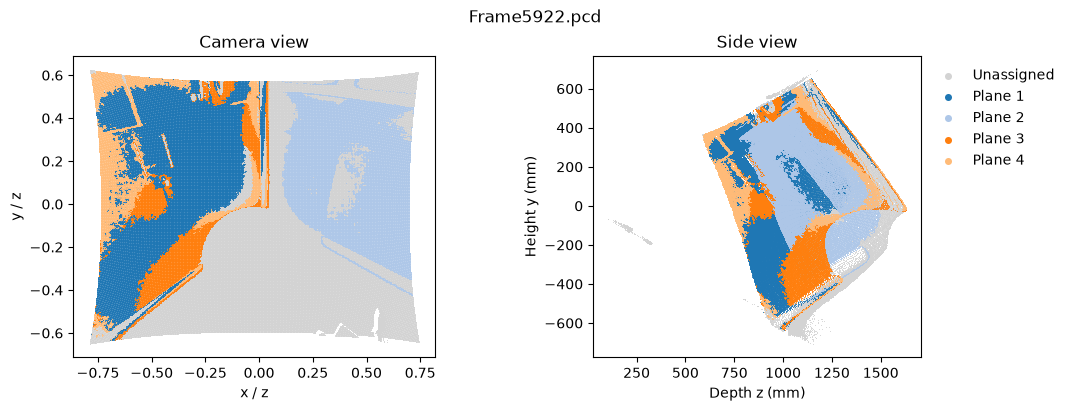

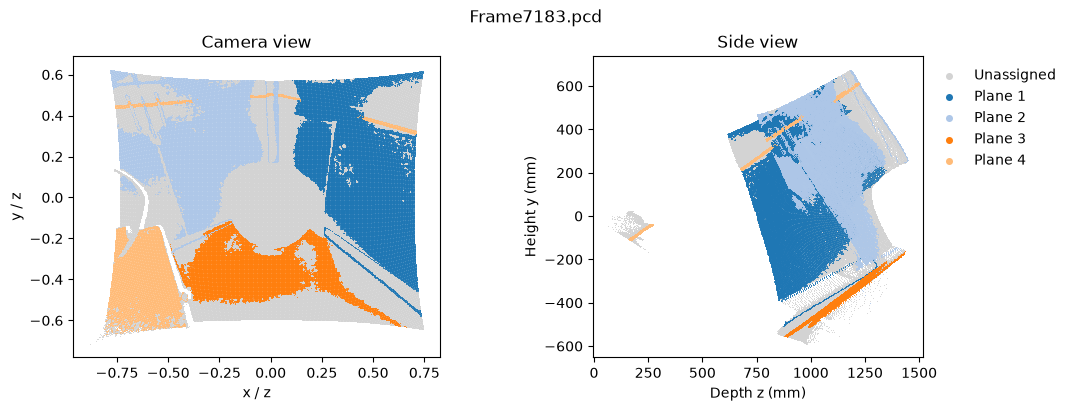

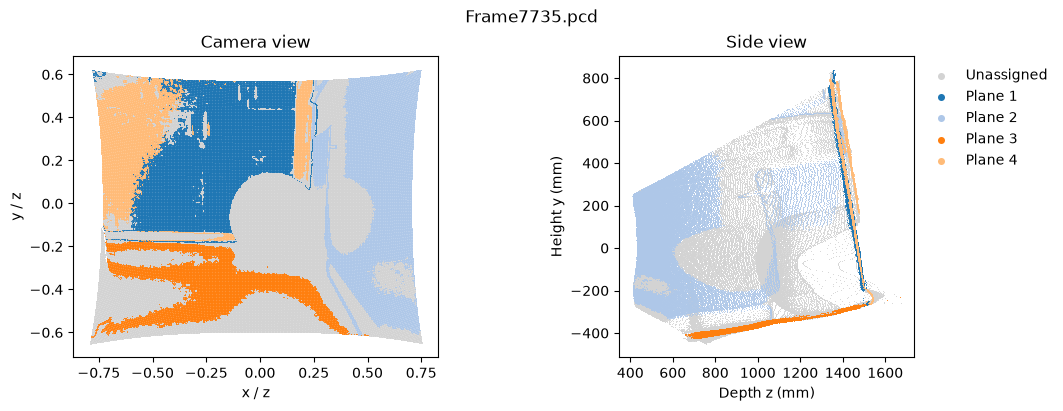

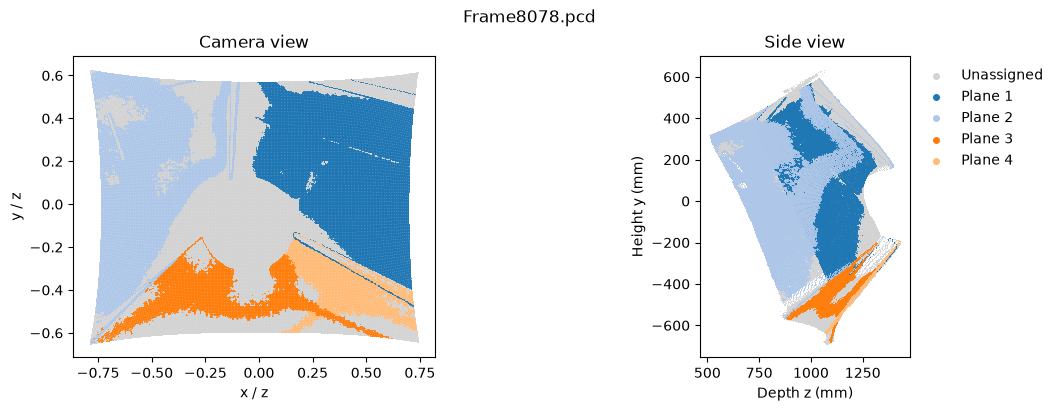

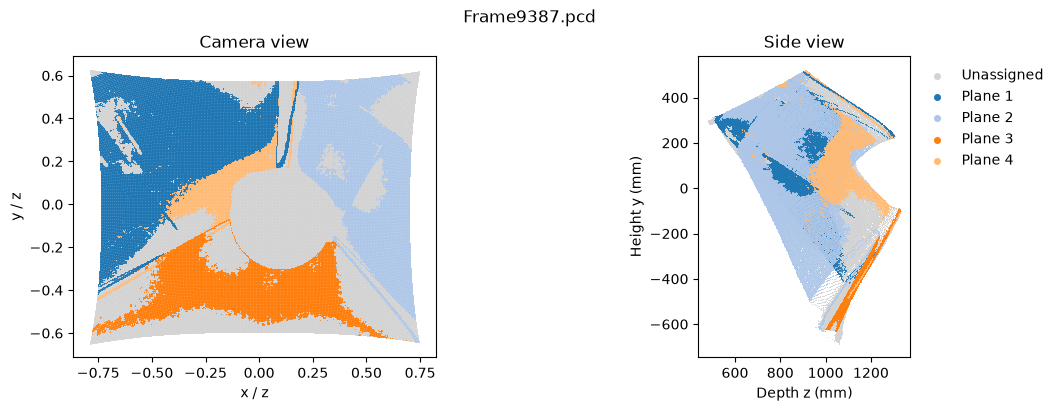

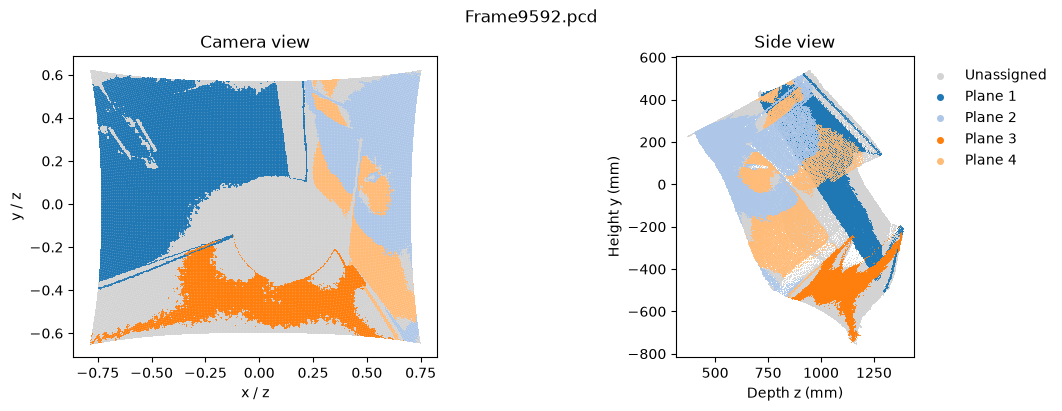

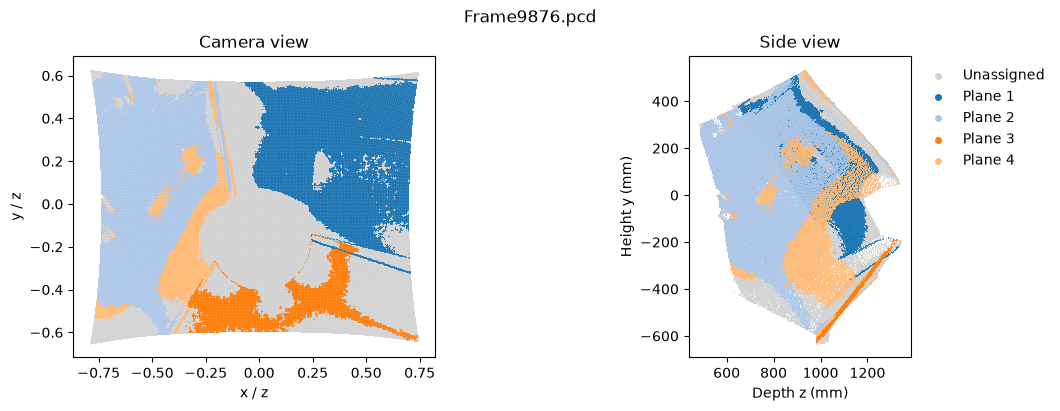

In [7]:
import matplotlib.pyplot as plt

for filename, (points, planes, plane_labels) in frame_results.items():
    fig, (front, side) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for label in range(len(planes) + 1):
        x, y, z = points[plane_labels == label].T
        color = "lightgrey" if label == 0 else plt.cm.tab20((label - 1) % 20)
        name = "Unassigned" if label == 0 else f"Plane {label}"
        front.scatter(x / z, y / z, s=0.4, color=color, linewidths=0, label=name)
        side.scatter(z, y, s=0.4, color=color, linewidths=0)

    front.set(title="Camera view", xlabel="x / z", ylabel="y / z", aspect="equal")
    side.set(title="Side view", xlabel="Depth z (mm)", ylabel="Height y (mm)", aspect="equal")
    side.legend(*front.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(1, 1),
                markerscale=8, frameon=False)
    fig.suptitle(filename)
    plt.show()

## 5. Fit a sphere to four example points

All four surface points are equally far from the center ( the first point as a local origin ).

In [8]:
def sphere_from_four(sample):
    origin = sample[0]
    delta = sample[1:] - origin
    try:
        shift = np.linalg.solve(2 * delta, np.sum(delta ** 2, axis=1))
    except np.linalg.LinAlgError:
        return None
    return origin + shift, np.linalg.norm(shift)

# Example sphere centered at (10, 20, 500) with radius 5 mm.
sample = np.array([[15, 20, 500], [10, 25, 500], [10, 20, 505], [5, 20, 500]])
center, radius = sphere_from_four(sample)
print(f"Center: {center} mm, radius: {radius:g} mm")

Center: [ 10.  20. 500.] mm, radius: 5 mm


## 6. Find the visible sphere with RANSAC

Pick four nearby points. If the first falls on the ball, its neighbors have a better chance of sharing the same surface. We draw from up to 6,000 random points across the whole frame to keep the search fast. The neighborhood radius is one tenth of the sampled scene diagonal. We discard radii above one quarter of that diagonal because a very large sphere can fit a flat wall.

A measured point supports a sphere if its distance from the center is within the tolerance of the radius. We also check that the surface faces the camera. At a point on the sphere the outward normal points away from the center, and the viewing ray points away from the camera. On the visible side these directions have a nonpositive dot product. Score each proposal on the sample, then classify every valid point with the winning model. All input points are eligible, including points provisionally assigned to planes.

In [9]:
def visible_sphere_inliers(points, center, radius, tolerance_mm):
    offsets = points - center
    errors = np.abs(np.linalg.norm(offsets, axis=1) - radius)
    
    # A visible surface normal faces the camera at the origin.
    facing_camera = np.sum(offsets * points, axis=1) <= 0
    
    return (errors <= tolerance_mm) & facing_camera


def find_sphere(points, tolerance_mm=SPHERE_TOLERANCE_MM):
    rng = np.random.default_rng(RANDOM_SEED)
    sample = points[rng.choice(len(points), min(6000, len(points)), replace=False)]
    scene_width = np.linalg.norm(np.ptp(sample, axis=0))
    best_count = 0
    best = None
    for _ in range(SPHERE_TRIALS):
        anchor = sample[rng.integers(len(sample))]
        nearby = sample[np.linalg.norm(sample - anchor, axis=1) < scene_width / 10]
        if len(nearby) < 4:
            continue
        sphere = sphere_from_four(nearby[rng.choice(len(nearby), 4, replace=False)])
        if sphere is None:
            continue
        center, radius = sphere
        if radius > scene_width / 4:
            continue
        count = np.count_nonzero(visible_sphere_inliers(sample, center, radius, tolerance_mm))
        if count > best_count:
            best_count = count
            best = sphere

    if best is None:
        raise ValueError("Could not fit a sphere to this frame.")
    center, radius = best
    return center, radius, visible_sphere_inliers(points, center, radius, tolerance_mm)

In [10]:
sphere_results = {}
for filename, (points, _, _) in frame_results.items():
    center, radius, mask = find_sphere(points)
    sphere_results[filename] = (center, radius, mask)
    print(f"{filename}: radius {radius:.1f} mm, {mask.sum():,} sphere points")

Frame15439.pcd: radius 215.4 mm, 18,445 sphere points
Frame18031.pcd: radius 213.2 mm, 15,333 sphere points
Frame4994.pcd: radius 213.2 mm, 10,465 sphere points
Frame5551.pcd: radius 233.0 mm, 14,319 sphere points
Frame5922.pcd: radius 209.8 mm, 18,040 sphere points
Frame7183.pcd: radius 197.1 mm, 11,387 sphere points
Frame7735.pcd: radius 230.1 mm, 14,711 sphere points
Frame8078.pcd: radius 205.7 mm, 13,144 sphere points
Frame9387.pcd: radius 211.0 mm, 15,214 sphere points
Frame9592.pcd: radius 215.9 mm, 17,204 sphere points
Frame9876.pcd: radius 211.2 mm, 16,908 sphere points


### Inspect the sphere in the camera view

Grey shading shows depth. Yellow marks the sphere inliers. Check that the yellow points fill a round patch and whether any extend onto a nearby wall.

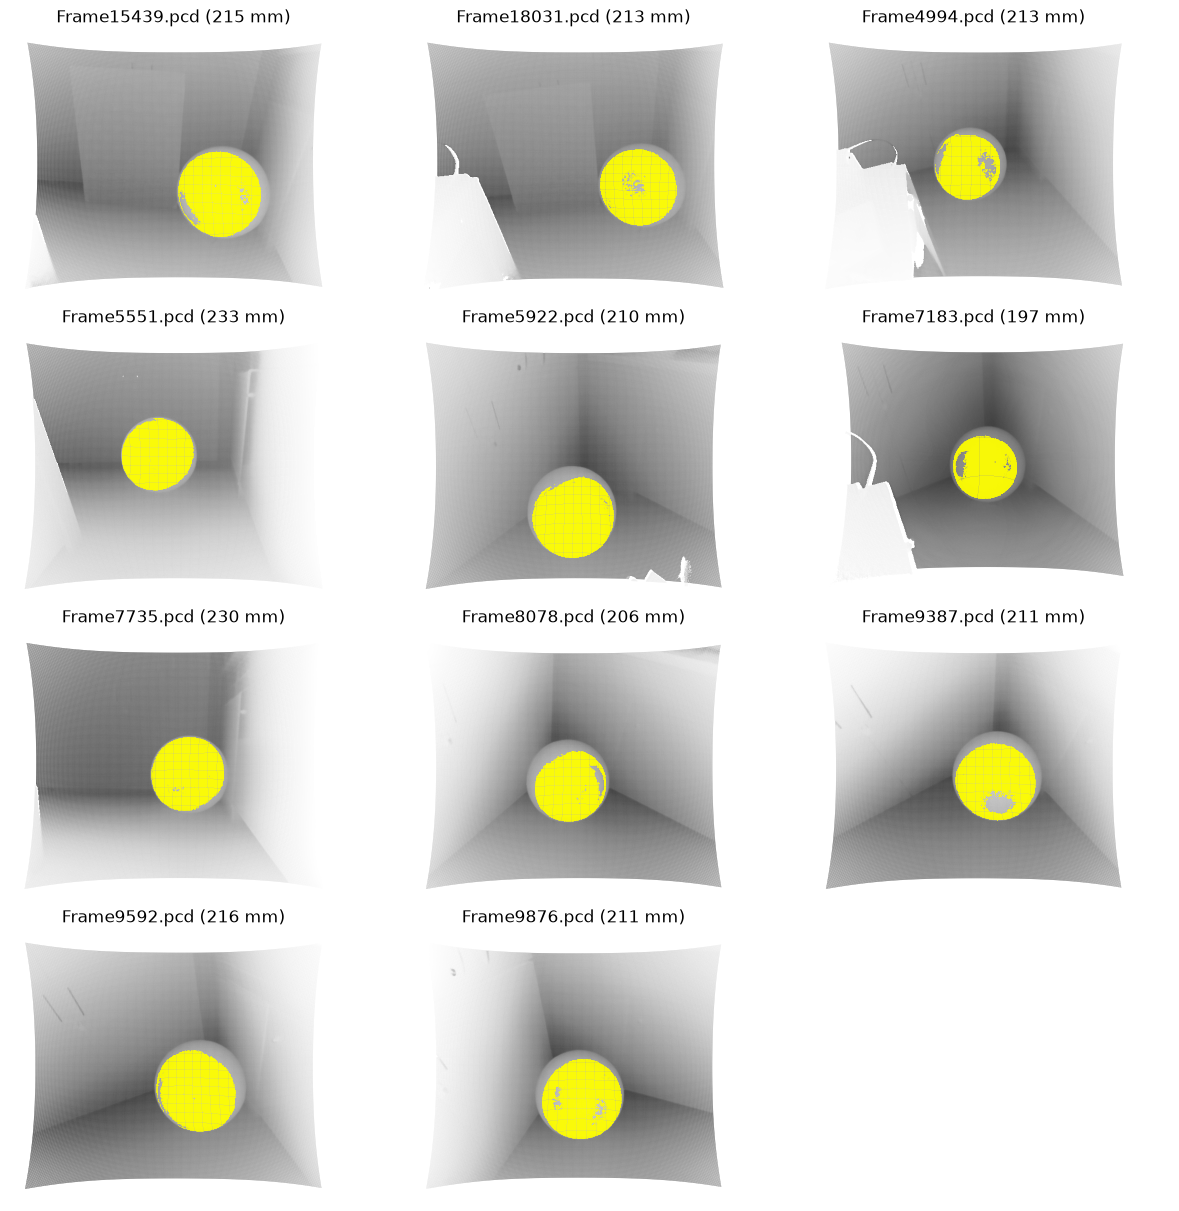

In [11]:
columns = min(3, len(frame_results))
rows = math.ceil(len(frame_results) / columns)
fig, axes = plt.subplots(rows, columns, squeeze=False, figsize=(4 * columns, 3 * rows),
                         constrained_layout=True)
for ax in axes.flat:
    ax.set_axis_off()
for ax, (filename, (points, _, _)) in zip(axes.flat, frame_results.items()):
    center, radius, mask = sphere_results[filename]
    x, y, z = points.T
    ax.scatter(x / z, y / z, c=z, cmap="Greys", s=0.2, linewidths=0)
    ax.scatter(x[mask] / z[mask], y[mask] / z[mask], color="yellow", s=0.2, linewidths=0)
    ax.set(aspect="equal", title=f"{filename} ({radius:.0f} mm)")
plt.show()

## 7. Combine the sphere and planes

A point near the ball's contact with a wall can pass both distance tests. Give sphere inliers label −1 first, then fit planes using only the remaining points. Plane labels start at 1, and 0 means unassigned. The minimum plane size still uses the original valid point count. Point order is preserved so each XYZ row has a matching RGB row for export.

In [12]:
from colorsys import hsv_to_rgb

def label_colors(plane_count):
    # Rows are unassigned, planes 1 through N, then sphere (index -1).
    palette = [[160, 160, 160]]
    for i in range(plane_count):
        hue = (0.6 + i * 0.618) % 1
        palette.append([round(255 * v) for v in hsv_to_rgb(hue, 0.8, 0.85)])
    palette.append([255, 255, 0])
    return np.array(palette, dtype=np.uint8)

combined_results = {}
for filename, (points, _, _) in frame_results.items():
    _, _, sphere_mask = sphere_results[filename]
    planes, labels = segment_planes(points, sphere_mask)
    colors = label_colors(len(planes))[labels]
    combined_results[filename] = (planes, labels, colors)

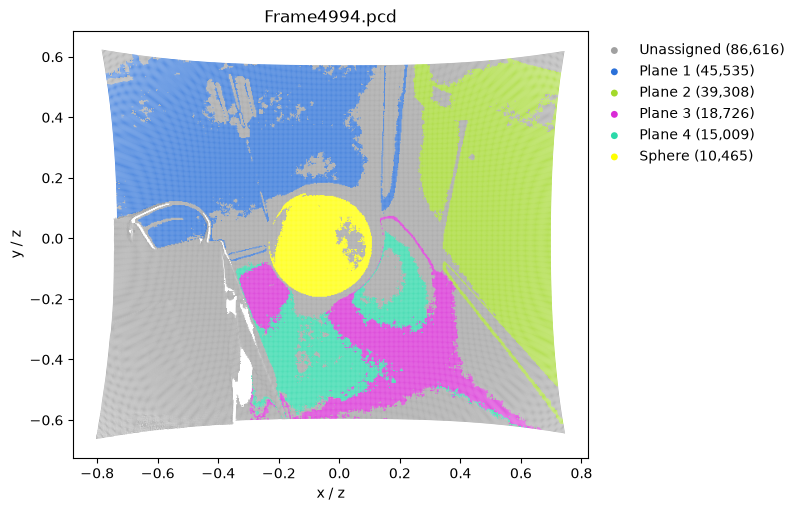

In [13]:
# Inspect one selected frame in detail.
filename = "Frame4994.pcd" if "Frame4994.pcd" in combined_results else next(iter(combined_results))
points = frame_results[filename][0]
planes, labels, colors = combined_results[filename]
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for label in [0, *range(1, len(planes) + 1), -1]:
    mask = labels == label
    if not mask.any():
        continue
    x, y, z = points[mask].T
    name = {-1: "Sphere", 0: "Unassigned"}.get(label, f"Plane {label}")
    ax.scatter(x / z, y / z, c=colors[mask] / 255, s=0.5, linewidths=0,
               label=f"{name} ({mask.sum():,})")
ax.set(aspect="equal", xlabel="x / z", ylabel="y / z", title=filename)
ax.legend(bbox_to_anchor=(1, 1), loc="upper left", markerscale=7, frameon=False)
plt.show()

### Compare plane tolerances
Changing the distance cutoff changes which points each plane claims. Later rounds search the remaining points, so a color can represent a different surface in each view. Yellow always marks the same sphere.

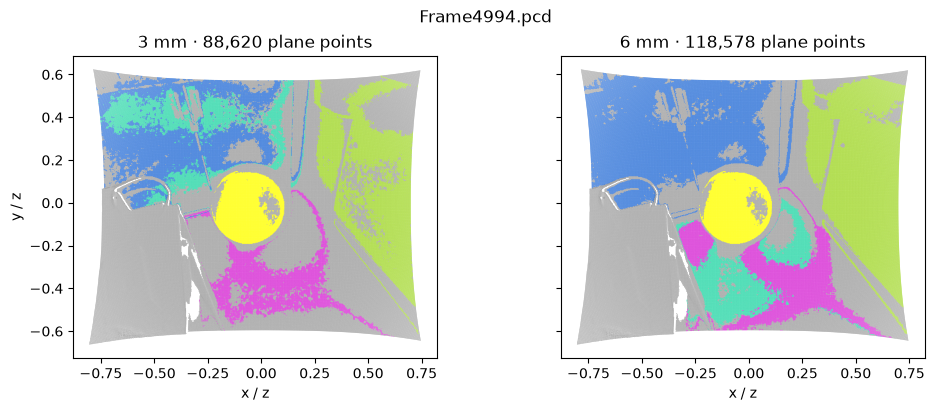

In [14]:
# Compare the same selected frame and sphere mask at two plane tolerances.
points = frame_results[filename][0]
sphere_mask = sphere_results[filename][2]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True,
                         constrained_layout=True)
fig.suptitle(filename)
for ax, tolerance in zip(axes, (3.0, 6.0)):
    models, trial_labels = segment_planes(points, sphere_mask, tolerance_mm=tolerance)
    rgb = label_colors(len(models))[trial_labels]
    x, y, z = points.T
    ax.scatter(x / z, y / z, c=rgb / 255, s=0.3, linewidths=0)
    assigned = np.count_nonzero(trial_labels > 0)
    ax.set(title=f"{tolerance:g} mm · {assigned:,} plane points", aspect="equal",
           xlabel="x / z")
axes[0].set_ylabel("y / z")
plt.show()

In [15]:
# Compare the percentage of valid points assigned to planes in each selected frame.
print(f"{'Frame':<17} {'3 mm':>8} {'6 mm':>8}")
for name, (cloud, _, _) in frame_results.items():
    sphere_mask = sphere_results[name][2]
    coverage = []
    for tolerance in (3.0, 6.0):
        _, labels = segment_planes(cloud, sphere_mask, tolerance_mm=tolerance)
        coverage.append(100 * np.mean(labels > 0))
    print(f"{name:<17} {coverage[0]:7.1f}% {coverage[1]:7.1f}%")

Frame                 3 mm     6 mm
Frame15439.pcd       39.1%    60.9%
Frame18031.pcd       34.2%    57.2%
Frame4994.pcd        41.1%    55.0%
Frame5551.pcd        36.9%    60.0%
Frame5922.pcd        45.7%    62.2%
Frame7183.pcd        23.7%    55.3%
Frame7735.pcd        39.5%    57.6%
Frame8078.pcd        43.5%    60.9%
Frame9387.pcd        44.1%    63.1%
Frame9592.pcd        43.9%    61.8%
Frame9876.pcd        43.8%    64.6%


At the four-plane limit, 6 mm increased coverage in all 11 course frames (39.6% to 59.9% of all valid points combined). The wall patches generally became more continuous. Some surfaces still received two colors, especially the lower surface in Frame4994. We use 6 mm as the working default.

### Let the support threshold determine the plane count
Keep the same sphere mask, seed and 6 mm tolerance. With no cap, RANSAC stops when the best remaining candidate has fewer than 3% of the original valid points. The first four fits follow the same sequence as the capped run.

In [16]:
for name, (cloud, _, _) in frame_results.items():
    sphere_mask = sphere_results[name][2]
    models, labels = segment_planes(cloud, sphere_mask, max_planes=None)
    extra = np.count_nonzero(labels > 4)
    print(f"{name}: {len(models)} plane candidates, {extra:,} points after plane 4")

Frame15439.pcd: 6 plane candidates, 15,785 points after plane 4
Frame18031.pcd: 8 plane candidates, 35,221 points after plane 4
Frame4994.pcd: 8 plane candidates, 32,590 points after plane 4
Frame5551.pcd: 6 plane candidates, 18,080 points after plane 4
Frame5922.pcd: 6 plane candidates, 15,902 points after plane 4
Frame7183.pcd: 8 plane candidates, 45,532 points after plane 4
Frame7735.pcd: 8 plane candidates, 37,348 points after plane 4
Frame8078.pcd: 7 plane candidates, 36,981 points after plane 4
Frame9387.pcd: 7 plane candidates, 27,436 points after plane 4
Frame9592.pcd: 7 plane candidates, 27,963 points after plane 4
Frame9876.pcd: 7 plane candidates, 28,403 points after plane 4


Across these 11 frames the support rule accepted 6–8 candidates. Coverage rose from 59.9% to 73.3%. On Frame4994, plane 8 is almost parallel to plane 1 (about 0.5 degrees), and its inlier centroid is only 9.8 mm from plane 1. The previews suggest that some later detections split one surface into bands.

## 8. Automatic tolerances and a one-step plane refit

Use small neighborhoods to estimate how thick a measured surface looks. Fit a plane to each neighborhood, take the median absolute deviation of its perpendicular residuals, and multiply by 1.4826 to estimate a noise scale. Taking the median across neighborhoods reduces the influence of edges and curved patches. The final cutoffs are four noise scales for planes and three and a half for spheres. These multipliers are fixed heuristics. The distances in millimeters change with the input.

After RANSAC finds a plane, fit it again using all winning inliers and update membership once. The normal is the direction with the least spread in those points. Earlier sections keep the fixed-tolerance experiments for comparison.


On Frame4994, keeping the sphere mask and 6 mm cutoff fixed, refitting once reduced the plane count from eight to six and plane coverage from 151,168 to 144,567 points. With adaptive tolerances the same frame produced eight candidates. The cutoff also changes which points remain for later fits.

In [17]:
def refit_plane(inliers):
    """The least-squares plane passes through the mean of its points."""
    center = inliers.mean(axis=0)
    centered = inliers - center
    _, axes = np.linalg.eigh(centered.T @ centered)
    normal = axes[:, 0]  # Direction in which the inliers vary least.
    return normal, normal @ center


def estimate_surface_noise(points):
    """Estimate the thickness of a typical local surface in this frame."""
    rng = np.random.default_rng(RANDOM_SEED)
    sample = points[rng.choice(len(points), min(len(points), 10000), replace=False)]
    if len(sample) < 4:
        raise ValueError("At least four valid points are required.")
    scales = []
    for anchor in sample[rng.choice(len(sample), min(64, len(sample)), replace=False)]:
        distances = np.sum((sample - anchor) ** 2, axis=1)
        k = min(40, len(sample))
        patch = sample[np.argpartition(distances, k - 1)[:k]]
        normal, offset = refit_plane(patch)
        residuals = patch @ normal - offset
        mad = np.median(np.abs(residuals - np.median(residuals)))
        scales.append(1.4826 * mad)
    precision = np.finfo(float).eps * max(1.0, np.max(np.abs(sample))) * 32
    return max(np.median(scales), precision)

In [18]:
def segment_frame(points):
    noise = estimate_surface_noise(points)
    plane_tolerance = 4 * noise
    sphere_tolerance = 3.5 * noise
    _, _, sphere_mask = find_sphere(points, tolerance_mm=sphere_tolerance)
    planes, labels = segment_planes(points, sphere_mask, tolerance_mm=plane_tolerance,
                                   max_planes=None, refine=True)
    colors = label_colors(len(planes))[labels]
    return labels, colors, plane_tolerance, sphere_tolerance

for name, (cloud, _, _) in frame_results.items():
    labels, _, plane_tol, sphere_tol = segment_frame(cloud)
    print(f"{name}: plane {plane_tol:.2f} mm, sphere {sphere_tol:.2f} mm, "
          f"{labels.max()} plane candidates, {(labels == -1).sum():,} sphere points")

Frame15439.pcd: plane 6.17 mm, sphere 5.40 mm, 6 plane candidates, 18,934 sphere points
Frame18031.pcd: plane 5.97 mm, sphere 5.22 mm, 6 plane candidates, 15,586 sphere points
Frame4994.pcd: plane 5.69 mm, sphere 4.98 mm, 8 plane candidates, 10,454 sphere points
Frame5551.pcd: plane 6.02 mm, sphere 5.27 mm, 7 plane candidates, 14,371 sphere points
Frame5922.pcd: plane 5.17 mm, sphere 4.52 mm, 6 plane candidates, 17,769 sphere points
Frame7183.pcd: plane 5.46 mm, sphere 4.78 mm, 8 plane candidates, 10,778 sphere points
Frame7735.pcd: plane 5.03 mm, sphere 4.40 mm, 8 plane candidates, 14,109 sphere points
Frame8078.pcd: plane 4.36 mm, sphere 3.81 mm, 8 plane candidates, 11,822 sphere points
Frame9387.pcd: plane 5.15 mm, sphere 4.50 mm, 7 plane candidates, 14,581 sphere points
Frame9592.pcd: plane 5.35 mm, sphere 4.68 mm, 7 plane candidates, 16,931 sphere points
Frame9876.pcd: plane 4.21 mm, sphere 3.68 mm, 7 plane candidates, 14,095 sphere points


---

### Command-line program Creation ( AI MADE )

Run the next cell to generate main.py beside this notebook from the same functions.

run `python main.py Frame4994.pcd Frame4994.ply`

In [19]:
def write_ply(path, points, colors):
    header = ("ply\nformat ascii 1.0\n"
              f"element vertex {len(points)}\n"
              "property double x\nproperty double y\nproperty double z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header")
    np.savetxt(path, np.column_stack((points, colors)), header=header, comments="",
               fmt="%.12g %.12g %.12g %d %d %d")

def main():
    import argparse
    parser = argparse.ArgumentParser(description="Color the sphere and planes in an ASCII PCD.")
    parser.add_argument("input_pcd")
    parser.add_argument("output_ply")
    args = parser.parse_args()
    points, _, _ = read_pcd(args.input_pcd)
    _, colors, plane_tol, sphere_tol = segment_frame(points)
    write_ply(args.output_ply, points, colors)
    print(f"Saved {len(points):,} points. Plane tolerance {plane_tol:.2f} mm, "
          f"sphere tolerance {sphere_tol:.2f} mm.")

In [20]:
import inspect

functions = [read_pcd, refit_plane, estimate_surface_noise, find_plane, segment_planes,
             sphere_from_four, visible_sphere_inliers, find_sphere, label_colors,
             segment_frame, write_ply, main]
imports = "import math\nimport os\nfrom colorsys import hsv_to_rgb\n\nimport numpy as np"
settings = ["MAX_PLANES", "PLANE_TOLERANCE_MM", "MIN_PLANE_FRACTION", "RANSAC_TRIALS",
            "RANDOM_SEED", "SPHERE_TRIALS", "SPHERE_TOLERANCE_MM"]
constants = "\n".join(f"{name} = {globals()[name]!r}" for name in settings)
source = "\n\n\n".join([imports, constants, *(inspect.getsource(fn).rstrip() for fn in functions),
                         'if __name__ == "__main__":\n    main()'])
(folder / "main.py").write_text(source + "\n", encoding="utf-8")

8674